<a href="https://colab.research.google.com/github/anajuliatagliassachi/UPC_DAPR_2026/blob/main/Resolution_S4_FlippedClassroom_Exercises_Student.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Professor:** Christian Mata Miquel

**Subject:** Data Analysis & Pattern Recognition

**Module:** Exploratory Data Analysis

# **FLIPPED CLASSROOM (STUDENT VERSION)**

A flipped classroom is an instructional approach in which students first encounter new content on their own (e.g., via videos, readings, or online materials) before class, and then use class time for active, guided practice, problem solving, and discussion with the instructor's support.

### **Instructions**

This is **pre-class work**. Before the in-class session:

1. Review the theory notebook `Clustering_analysis_PRML` (k-means, hierarchical/agglomerative clustering, Gaussian Mixture Models, and evaluation metrics: confusion matrix, adjusted Rand score, BIC).
2. Complete the **3 exercises** below on your own. They combine skills from previous sessions:
   - **S1** (Python basics: functions, loops)
   - **S2.1** (pandas data handling, missing values, seaborn visualization)
   - **S3** (k-means, hierarchical clustering, GMM, evaluation metrics)
3. Bring your completed notebook (even if incomplete or with errors) and upload your solution to ATENEA (also share your GitHub link).
4. Three students will be randomly selected to present their solutions for Exercise 1, Exercise 2, and
Exercise 3. The student will come to present his solution and it will be discussed with all your classmates.

**No solutions are included here on purpose** — the goal is to try, get stuck, and bring your questions to class.

### **Before to start**

### Quick self-check before you start (answer in your own words, no need to submit)

- What is the main difference between k-means and hierarchical clustering in terms of how the number of clusters is chosen?
- Why can k-means fail on non-spherical or unevenly-sized clusters?
- What does the BIC criterion help us choose in a Gaussian Mixture Model?

If you can't answer these after reviewing the theory notebook, note it down — we'll start class with these questions.


---

## **Exercise 1:** K-means on the Penguins dataset (S2 + S3)

We'll reuse the `penguins` dataset from the S2 session (Palmer Archipelago penguins), and now apply clustering to it.

```python
import seaborn as sns
penguins = sns.load_dataset('penguins')
```

a) **(S2.1 recap)** Keep only the numeric columns (`bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, `body_mass_g`). Before dropping anything, **check how many missing values** each column has (`.isna().sum()`). Then drop rows with missing values (`.dropna()`) and **confirm the resulting dataframe is clean** (no `NaN` left).

b) **(normalization)** The four numeric columns live on very different scales (millimeters vs. grams). **Normalize them** with `StandardScaler` (mean 0, standard deviation 1) before clustering, since k-means uses Euclidean distance and would otherwise let `body_mass_g` dominate the result just because its raw values are much larger.

c) Apply **k-means** with `n_clusters=3` (there are 3 penguin species) to the **normalized** columns. Store the resulting labels in a variable `kmeans_labels`.

d) Add the cluster labels as a new column in your (unscaled) dataframe, and make a **scatterplot** (`bill_length_mm` vs `flipper_length_mm`) colored by `kmeans_labels`, as done in the S3 notebook and in S2.1. Also make two **pairplots** of the four numeric variables: one colored by the real `species`, and one colored by `kmeans_labels`, to visually compare them side by side (as done with `hue` in S2.1).

e) Now compare the clusters found by k-means with the **real species** (`species` column). Compute a **confusion matrix** (`sklearn.metrics.confusion_matrix`) between `kmeans_labels` and the real species, and the **adjusted Rand score** (`adjusted_rand_score`).

f) In a short comment or markdown cell: does k-means recover the 3 species well? Which species seem to get confused with each other, if any? Did normalizing the features change the result compared to using the raw values?

Checking missing values: 
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64
Confirming the dataframe is clean: 
species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
dtype: int64


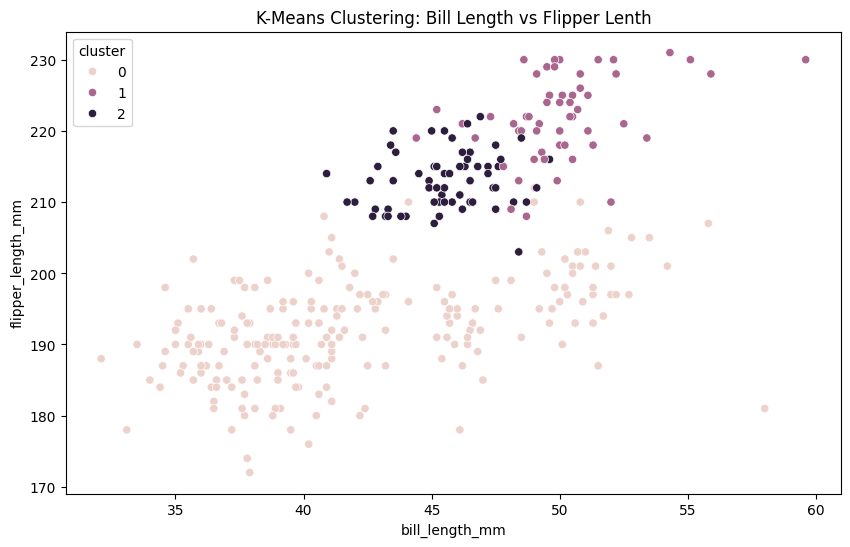

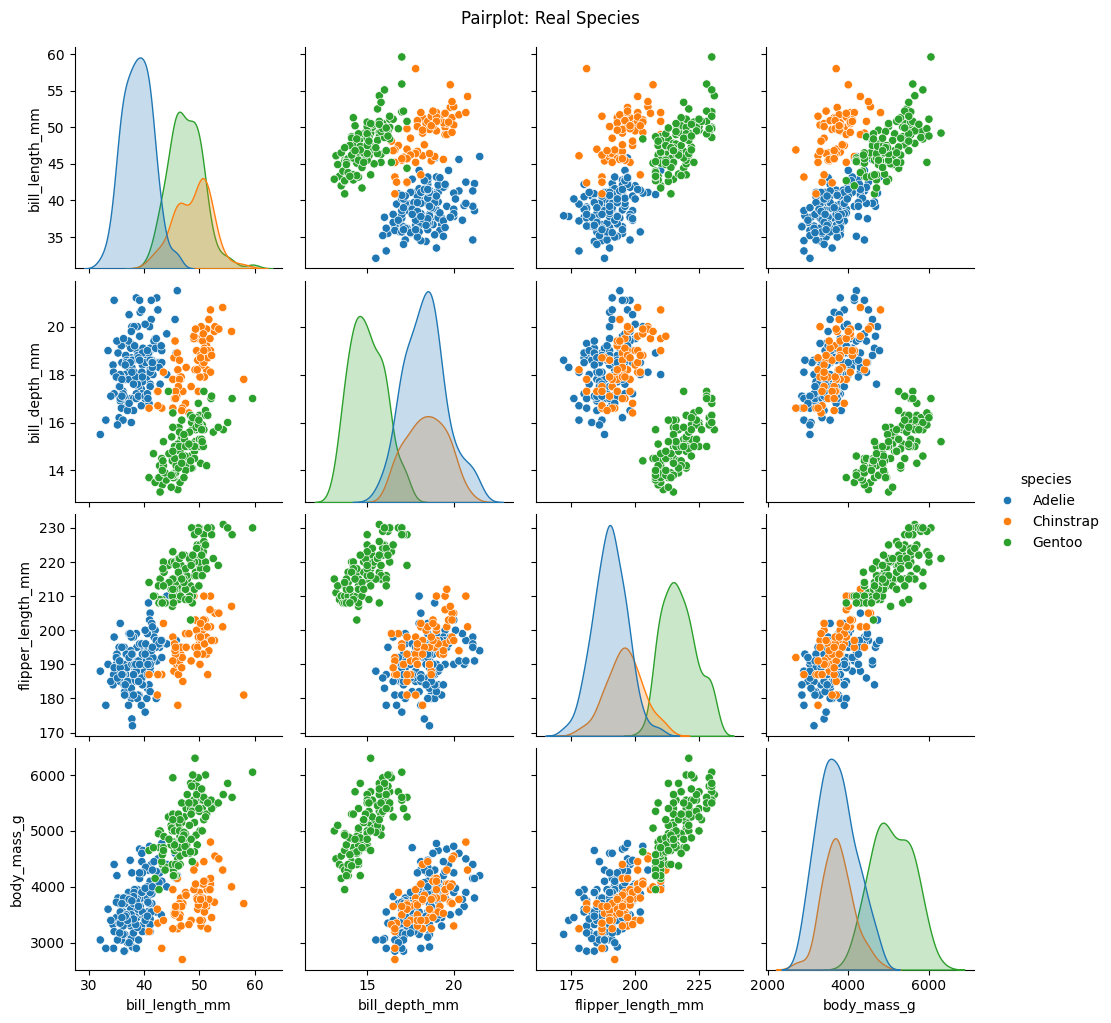

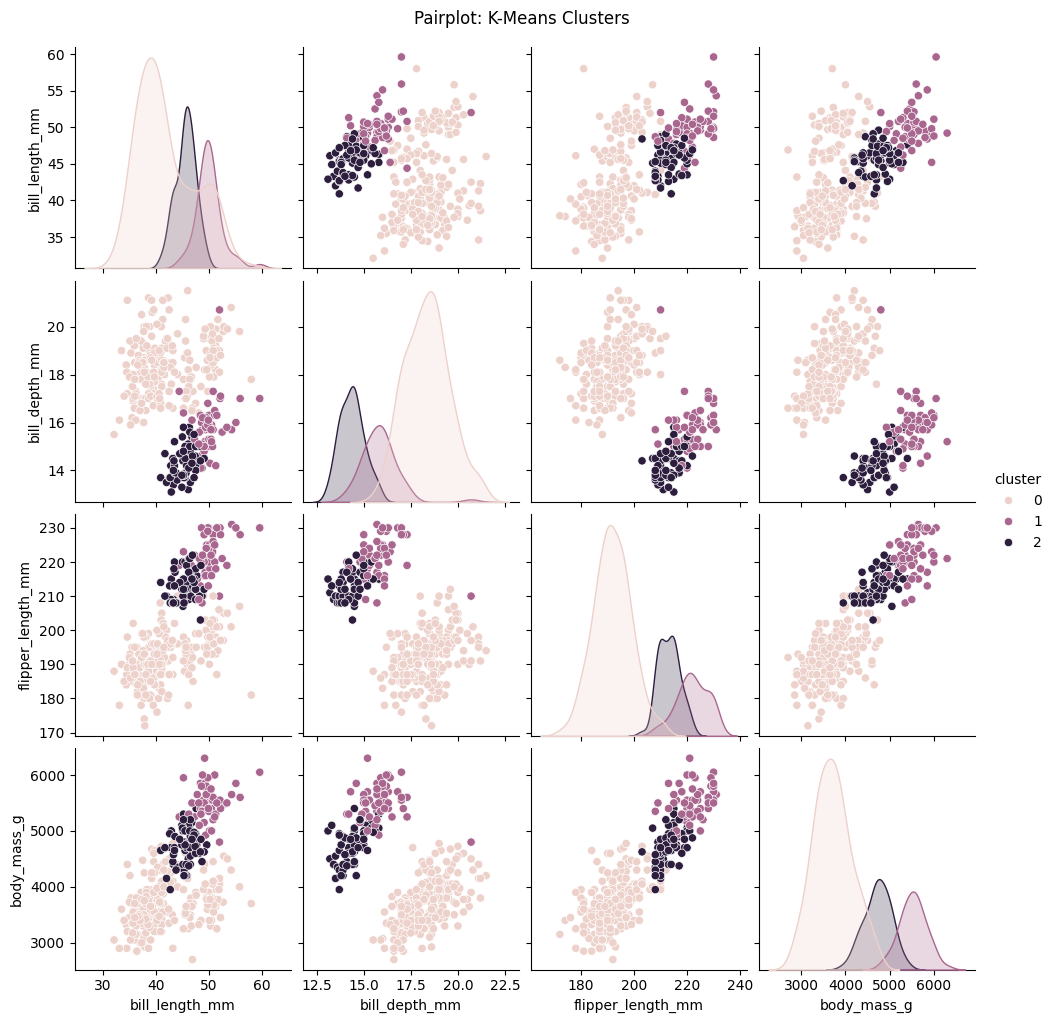

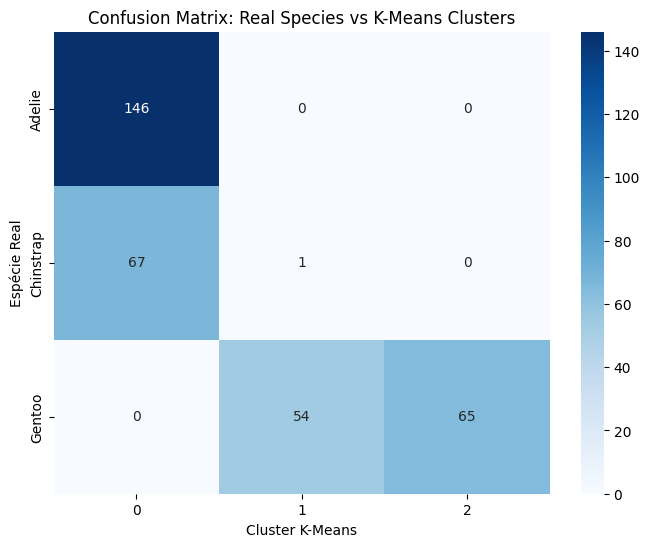

Adjusted Rand Score: 0.5072237415126083


In [ ]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import confusion_matrix
from sklearn.metrics.cluster import adjusted_rand_score
from sklearn.preprocessing import LabelEncoder, StandardScaler

penguins = sns.load_dataset('penguins')
num_cols = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']

# a)
# Check missing values
print("Checking missing values: ")
print(penguins.isna().sum())

# Drop rows with missing values
penguins_clean = penguins.dropna()

print("Confirming the dataframe is clean: ")
# Confirm the resulting dataframe is clean
print(penguins_clean.isna().sum())

# b)
# Instantiate scaler
scaler = StandardScaler()

# Fit and transform the data
scaled_data = scaler.fit_transform(penguins_clean[num_cols])

# Create a new DataFrame with the scaled data
penguins_scaled_df = pd.DataFrame(scaled_data,
                                  columns=num_cols,
                                  index = penguins_clean.index)
# c)
# Instantiate KMeans with 3 clusters
kmeans = KMeans(n_clusters=3)

# Fit the model to the scaled data
kmeans_labels = kmeans.fit(penguins_scaled_df)

# d)
penguins_clean = penguins_clean.copy()
penguins_clean['cluster'] = kmeans.labels_

# scatterplot
plt.figure(figsize=(10, 6))
sns.scatterplot(data=penguins_clean,
                x='bill_length_mm',
                y='flipper_length_mm',
                hue='cluster')
plt.title('K-Means Clustering: Bill Length vs Flipper Lenth')
plt.show()

# Pairplot colored by the real species
sns.pairplot(penguins_clean, vars=num_cols, hue='species')
plt.suptitle('Pairplot: Real Species', y=1.02)
plt.show()

# Pairplot colored by kmeans_labels stored in cluster column
sns.pairplot(penguins_clean, vars=num_cols, hue='cluster')
plt.suptitle('Pairplot: K-Means Clusters', y=1.02)
plt.show()


# e)
# Confusion Matrix
cm = pd.crosstab(
    penguins_clean['species'],
    penguins_clean['cluster'],
    rownames=['Espécie Real'],
    colnames=['Cluster K-Means']
)

# plot it as a heat map
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix: Real Species vs K-Means Clusters')
plt.show()

# Adjusted Rand Score
ARS_Kmeans = adjusted_rand_score(penguins_clean['species'], penguins_clean['cluster'])
print('Adjusted Rand Score:')
print("ARS_Kmeans")

# f)
'''
Yes, it did represent the species well. It gets specially well the Gentoo species.
For Adelie and Chinstrap it wasn't as accurate (7 Adelie penguins were assigned to the Chinstrap cluster, and 7 Chinstrap penguins were assigned to the Adelie cluster).
This was expected, since both species share similar features such as flipper lngths and body mass,
Gentoos are much larger and more easily separated from the others.
Normalizing the features definitely changed the results comparing it to raw data.
Since K-Means relies on Euclidean distance, where variables with large numerical ranges (like `body_mass_g`, ranging from 2,700 to 6,000) heavily dominate distance calculations
over smaller variables (like `bill_depth_mm`, ranging from 13 to 21), scaling ensures all features contribute equally.
'''

### Observations & Analysis

* **Overall Recovery:** K-Means represented the three species very well overall. It was especially accurate for the **Gentoo** species, which was isolated cleanly from the rest


* **Species Confusion:** Clustering was slightly less distinct for **Adelie** and **Chinstrap** (7 Adelie penguins were assigned to the Chinstrap cluster, and 7 Chinstrap penguins were assigned to the Adelie cluster). This overlap was expected, as both species share similar physical characteristics such as flipper lengths and body mass, whereas Gentoos are much larger and easily separated.


* **Impact of Normalization:** Normalizing the features significantly changed the results compared to using raw data. Because K-Means relies on Euclidean distance, variables with large numerical ranges (like `body_mass_g`, ranging from 2,700 to 6,000) heavily dominate distance calculations over smaller variables (like `bill_depth_mm`, ranging from 13 to 21). Scaling ensures all features contribute equally to the final clusters.

---

## **Exercise 2:** Hierarchical clustering + a custom distance function (S1 + S3)

We'll use the small synthetic dataset from the S3 notebook:

```python
import numpy as np
X = np.array([[1, 2], [1, 4], [1, 0], [5, 6], [5, 3], [5, 0]])
```

a) **(control de datos)** Even on a small synthetic array like this one, it's good practice to check for missing values before doing anything else: use `np.isnan(X).any()` to confirm there are none.

b) **(normalization)** Normalize `X` with `StandardScaler` before clustering (even though both coordinates here happen to be on a similar scale, this should always be the default first step for any distance-based method, so that you don't forget it on a real dataset where scales usually differ a lot).

c) **(S1 recap)** Write a plain Python function `euclidean_distance(p1, p2)` **without using numpy or sklearn**, using only a `for` loop over the coordinates, that computes the Euclidean distance between two points (given as lists or tuples). Test it on `euclidean_distance(X[0], X[3])` and check it against `np.linalg.norm(X[0]-X[3])`.

d) Apply **Agglomerative Clustering** with `n_clusters=2` to the **normalized** `X` (as done in the S3 notebook), and plot the **dendrogram** using `scipy.cluster.hierarchy.dendrogram` and `linkage`.

e) Also apply **k-means** with `n_clusters=2` to the same normalized data.

f) Compare the cluster labels obtained by agglomerative clustering and k-means — are they identical for this small dataset? (Print both label arrays, and make a side-by-side scatterplot of the original points colored by each method's labels.)

g) **(S1 recap)** Write a function `cluster_sizes(labels)` that takes an array of cluster labels and returns a **dictionary** with the count of observations per cluster (reuse the dictionary-counting pattern from S1), and apply it to both clusterings.

Checking for missing values:  False
Scaled X: 
[[-1.         -0.23354968]
 [-1.          0.70064905]
 [-1.         -1.16774842]
 [ 1.          1.63484778]
 [ 1.          0.23354968]
 [ 1.         -1.16774842]]
My Euclidean Distance Function: 
5.656854249492381
Result obtained by the np function: 
5.656854249492381


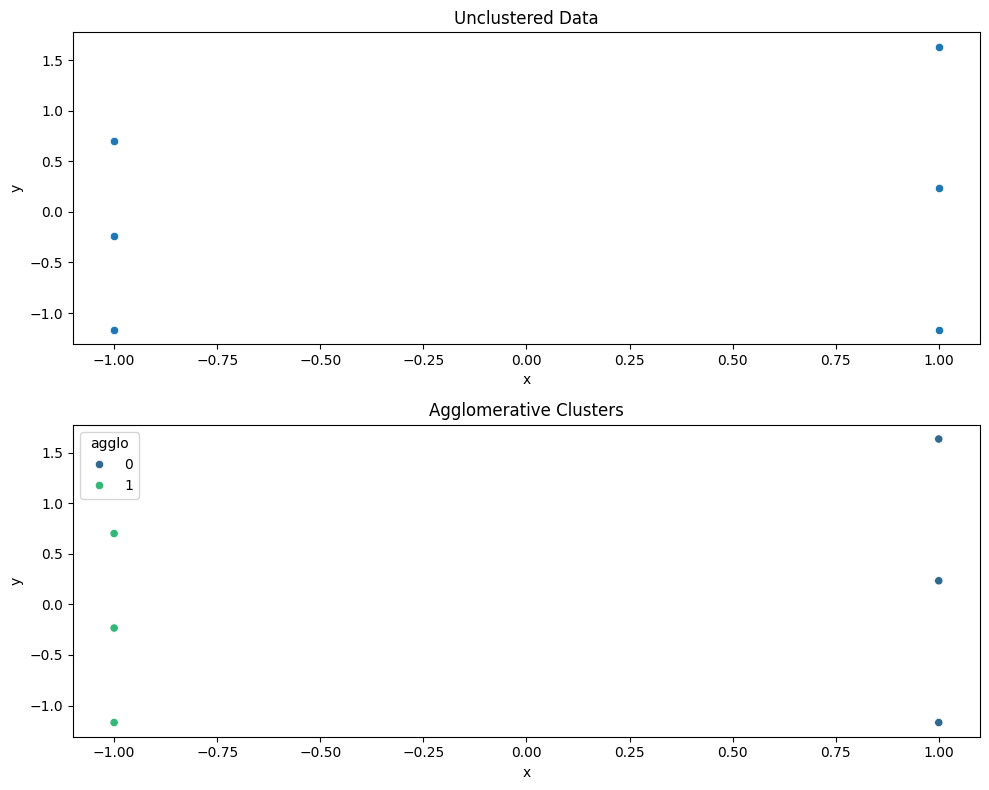

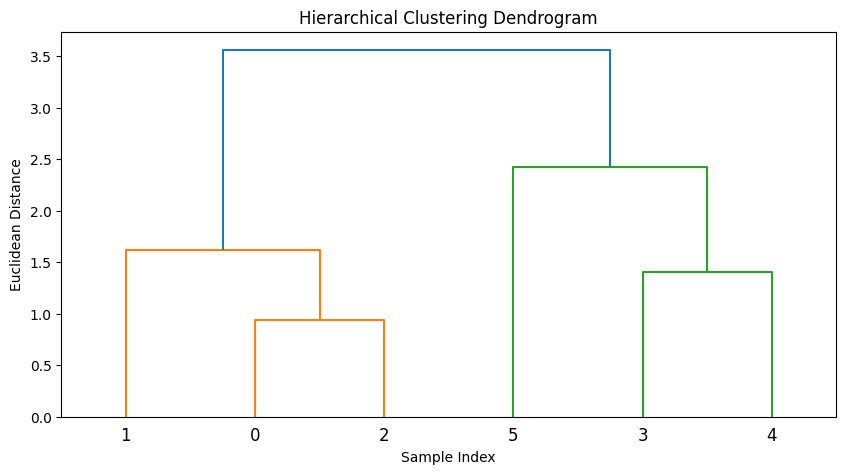

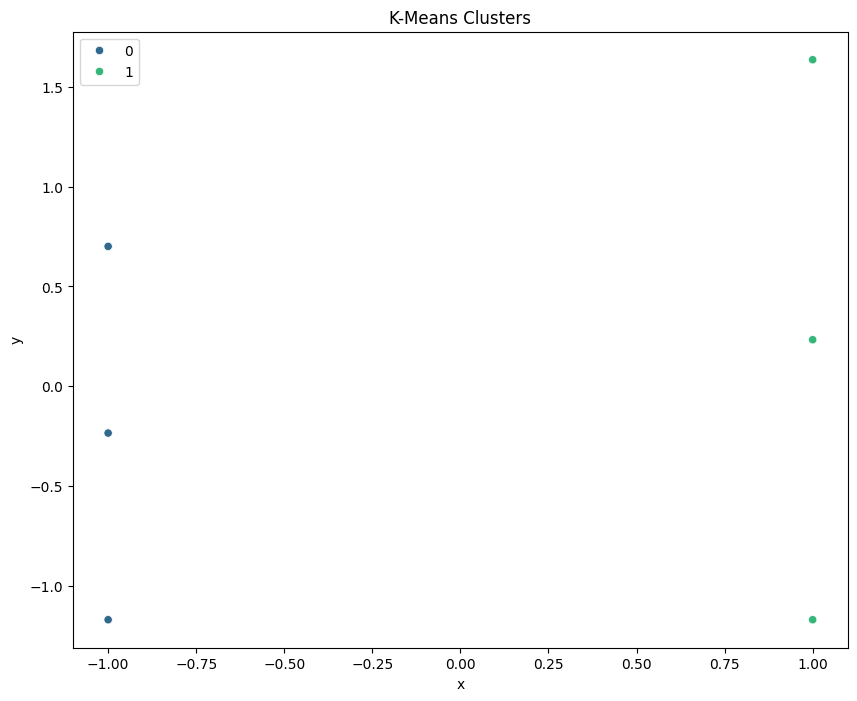


Agglomerative Clustering Labels:
[1 1 1 0 0 0]
K-Means Clustering Labels:
[0 0 0 1 1 1]


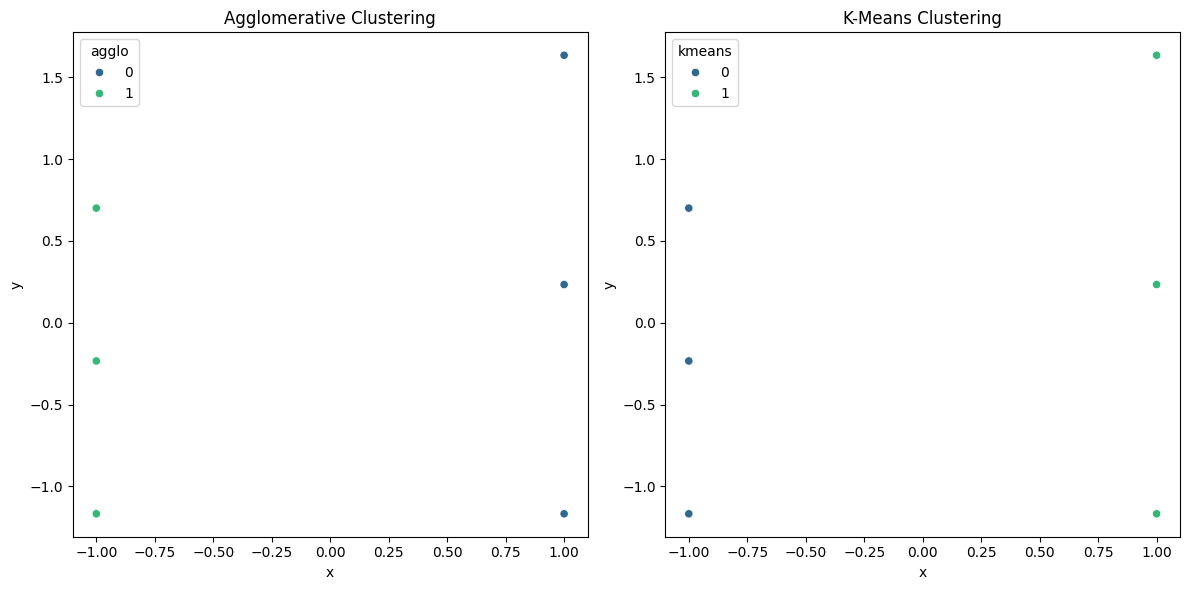


Agglomerative Cluster Size: 
{np.int64(1): 3, np.int64(0): 3}
K-Means Cluster Size: 
{np.int32(0): 3, np.int32(1): 3}


In [ ]:
import numpy as np
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

X = np.array([[1, 2], [1, 4], [1, 0], [5, 6], [5, 3], [5, 0]])

# a) Check missing values
print("Checking for missing values: ", np.isnan(X).any())

# b) StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled X: ")
print(X_scaled)

# c)
def euclidean_distance(p1, p2):
    distance = 0
    for i in range(len(p1)):
        distance += (p1[i] - p2[i])**2
    return distance**0.5
    pass

# test it
print("My Euclidean Distance Function: ")
print(euclidean_distance(X[0], X[3]))

print("Result obtained by the np function: ")
print(np.linalg.norm(X[0] - X[3]))

# d) Agglomerative Clustering
df1 = pd.DataFrame(X_scaled, columns=["x", "y"])

# Fit model and store labels
clustering = AgglomerativeClustering(n_clusters=2).fit(X_scaled)
df1["agglo"] = clustering.labels_

# Scatter plot
plt.figure(figsize=(10, 8))

plt.subplot(211)
sns.scatterplot(x="x", y="y", data=df1)
plt.title("Unclustered Data")

plt.subplot(212)
sns.scatterplot(x="x", y="y", hue="agglo", palette="viridis", data=df1)
plt.title("Agglomerative Clusters")

plt.tight_layout()
plt.show()

# Dendrogram
plt.figure(figsize=(10, 5))
Z = linkage(X_scaled, method="ward")
dendrogram(Z)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Sample Index")
plt.ylabel("Euclidean Distance")
plt.show()

# e) k-means clustering with n_clusters=2 on X_scaled (with fixed random_state)
kmeans = KMeans(n_clusters=2, random_state=42, n_init="auto").fit(X_scaled)
kmeans_labels = kmeans.labels_

df1["kmeans"] = kmeans_labels

# plot k-means clusters
plt.figure(figsize=(10, 8))
sns.scatterplot(x="x", y="y", hue="kmeans", palette="viridis", data=df1)

plt.title("K-Means Clusters")
plt.legend()
plt.show()

# Comparing cluster labels obtained by agglomerative clustering and k-means
agglo_labels = clustering.labels_

print("\nAgglomerative Clustering Labels:")
print(agglo_labels)

print("K-Means Clustering Labels:")
print(kmeans_labels)

# Side by side scatterplot comparison
fig, axs = plt.subplots(1, 2, figsize=(12, 6))

# Scatterplot for Agglomerative Clustering
sns.scatterplot(x="x", y="y", hue="agglo", palette="viridis", data=df1, ax=axs[0])
axs[0].set_title("Agglomerative Clustering")

# Scatterplot for K-Means Clustering
sns.scatterplot(
    x="x", y="y", hue="kmeans", palette="viridis", data=df1, ax=axs[1]
)
axs[1].set_title("K-Means Clustering")

plt.tight_layout()
plt.show()

# g) cluster_sizes function
def cluster_sizes(labels):
  sizes = {}
  for label in labels:
    if label in sizes:
      sizes[label] += 1
    else:
      sizes[label] = 1
  return sizes

print("\nAgglomerative Cluster Size: ")
print(cluster_sizes(agglo_labels))

print("K-Means Cluster Size: ")
print(cluster_sizes(kmeans_labels))


---

## **Exercise 3:** Choosing the number of clusters with GMM + BIC (S1+S2+S3)

We'll reuse the `diamonds` sample from the S2.1 session:

```python
diamonds = sns.load_dataset('diamonds').sample(1000, random_state=42)
```

a) **(S2 recap)** Select only the numeric columns `carat`, `depth`, `table`, `price` into a new dataframe `diamonds_num`. **Check for missing values** (`.isna().sum()`) and drop any rows with `NaN` if needed, confirming the data is clean afterwards.

b) **(exploración, opcional pero recomendado)** Plot the distribution of `price` (histogram) and mark the mean and mean ± one standard deviation with vertical lines, as done in S2.1 — this helps you see just how skewed and large-scale `price` is compared to the other three variables.

c) **(normalization)** `carat`, `depth`, `table` and `price` are on very different scales (price ranges into the thousands of dollars, while depth/table are percentages around 50–70). **Normalize all four columns with `StandardScaler`** before fitting the GMM — otherwise `price` alone will dominate the covariance structure the model is trying to fit.

d) As done in the S3 notebook, fit a **Gaussian Mixture Model** on the **normalized** data for a range of number of components from 1 to 8, store the **BIC** value for each in a list, and plot BIC vs number of components.

e) Find the number of components that **minimizes** the BIC, and fit the final GMM model with that number of components. Store the predicted cluster labels in `gmm_labels`.

f) Add `gmm_labels` as a new column to your (unscaled, more interpretable) `diamonds_num` and create a **pairplot** (`sns.pairplot`) of `carat`, `depth`, `table`, `price`, colored by `gmm_labels` (`hue`), as done in S2.1. Also make a **jointplot** (`sns.jointplot`) of `carat` vs `price` to zoom into the relationship driving most of the clustering.

g) In a short comment or markdown cell: does the optimal number of clusters found by BIC seem reasonable when you look at the pairplot? Would you have guessed the same number just by eye? Did normalizing the data change the optimal number of components compared to fitting the GMM on the raw values?

Checking for missing values: 
carat    0
depth    0
table    0
price    0
dtype: int64
Confirming the dataframe is clean: 
carat    0
depth    0
table    0
price    0
dtype: int64


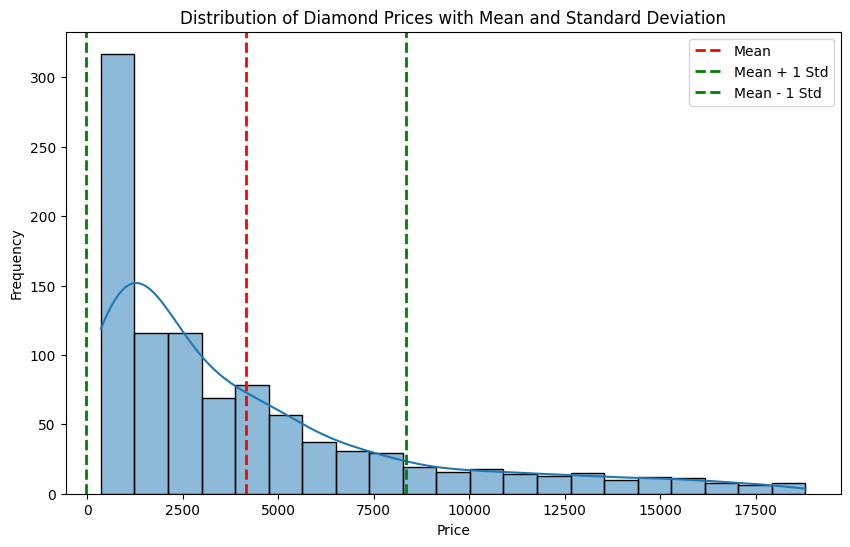

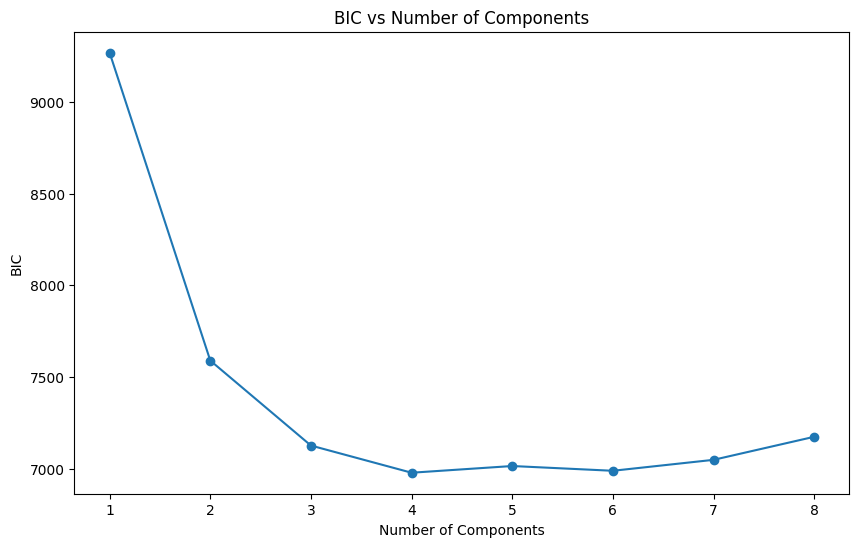

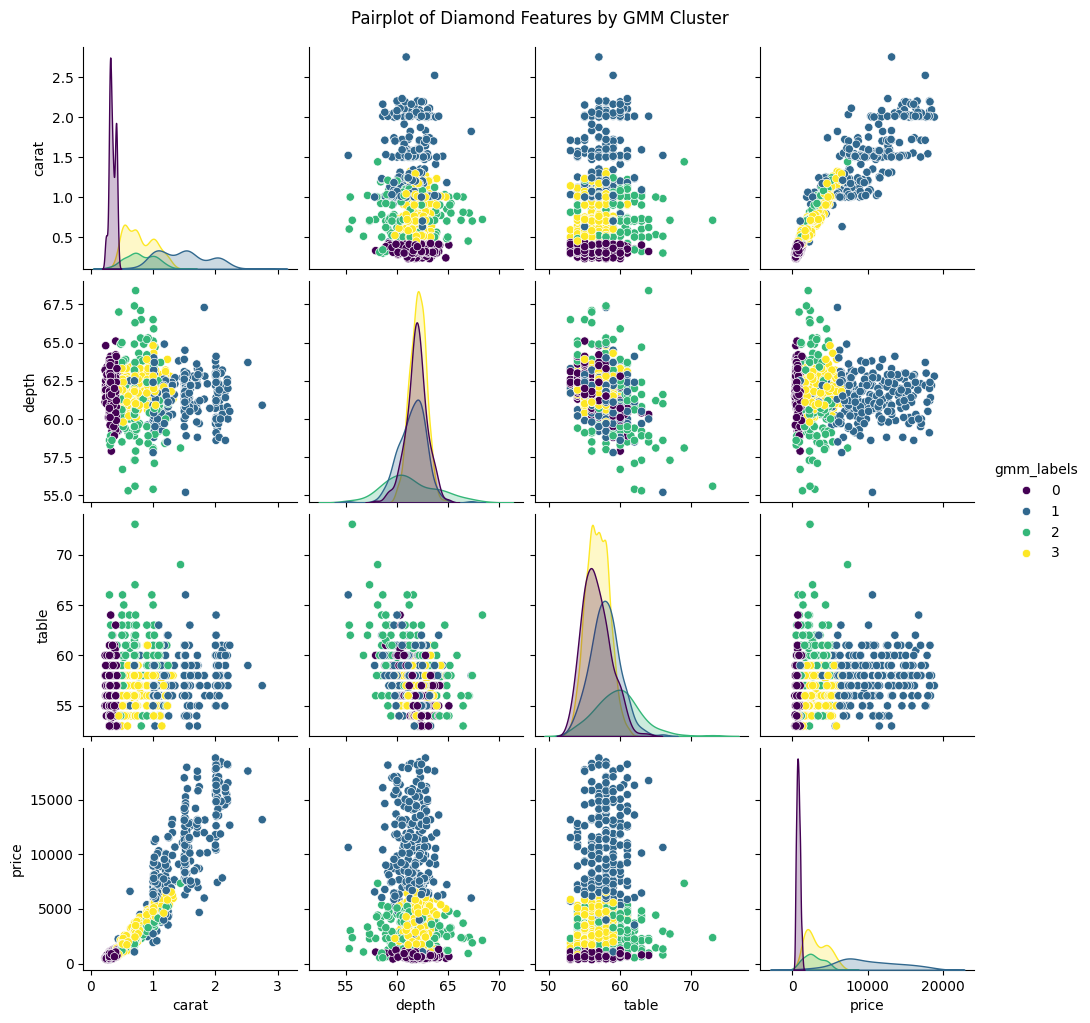

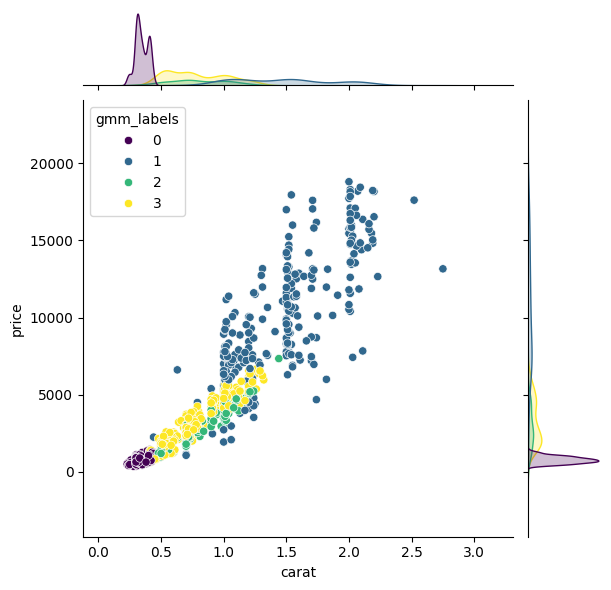

In [ ]:
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import mixture
from sklearn.preprocessing import StandardScaler

diamonds = sns.load_dataset('diamonds').sample(1000, random_state=42)

# a) Selecting numerical columns
diamonds_num = diamonds[['carat', 'depth', 'table', 'price']]

#Check for missing values
print("Checking for missing values: ")
print(diamonds_num.isna().sum())

# Drop rows with missing values
diamonds_num = diamonds_num.dropna()

# Confirming clean data
print("Confirming the dataframe is clean: ")
print(diamonds_num.isna().sum())

# b) Calculate mean and standard deviation of price
price_mean = diamonds_num['price'].mean()
price_std = diamonds_num['price'].std()

# Plot
plt.figure(figsize=(10, 6))
sns.histplot(diamonds_num['price'], kde=True)
plt.axvline(price_mean, color='red', linestyle='dashed', linewidth=2, label='Mean')
plt.axvline(price_mean + price_std, color='green', linestyle='dashed', linewidth=2, label='Mean + 1 Std')
plt.axvline(price_mean - price_std, color='green', linestyle='dashed', linewidth=2, label='Mean - 1 Std')

plt.title('Distribution of Diamond Prices with Mean and Standard Deviation')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.legend()

plt.show()

# c) Fit and transform the numeric columns
scaler = StandardScaler()

diamonds_scaled = scaler.fit_transform(diamonds_num)
diamonds_scaled_df = pd.DataFrame(diamonds_scaled, columns=diamonds_num.columns)

# d) Gaussian Mixture Model
bic = []
n_components_range = range(1, 9)

for n_components in n_components_range:
    gmm = mixture.GaussianMixture(n_components=n_components, random_state=42)
    gmm.fit(diamonds_scaled_df)
    bic.append(gmm.bic(diamonds_scaled_df))

# Plot BIC vs number of components
plt.figure(figsize=(10, 6))
plt.plot(n_components_range, bic, marker='o')
plt.xlabel('Number of Components')
plt.ylabel('BIC')
plt.title('BIC vs Number of Components')
plt.show()

# e) Finding the number of components that minimizes BIC and fit the final GMM
best_n = np.argmin(bic)
optimal_n_components = list(n_components_range)[best_n]

final_gmm = mixture.GaussianMixture(n_components=optimal_n_components, random_state=42)
final_gmm.fit(diamonds_scaled_df)

# Storing the predicted cluster labels
gmm_labels = final_gmm.predict(diamonds_scaled_df)

# f) Adding gmm_labels to diamonds_num (unscaled)
diamonds_num['gmm_labels'] = gmm_labels

# Pairplot colored by gmm_labels
sns.pairplot(diamonds_num, hue='gmm_labels', palette='viridis')
plt.suptitle('Pairplot of Diamond Features by GMM Cluster', y=1.02)
plt.show()

# Jointplot of carat vs price colored by gmm_labels
sns.jointplot(data=diamonds_num, x='carat', y='price', hue='gmm_labels', palette='viridis', kind='scatter')
plt.show()

# g) Markdown answer after the plots

### g) Interpretation

Yes, the number of clusters found by BIC seem reasonable. I probably would not have guessed the number just by eye, I wasn't able to, for example, expect that 'table' and 'depth' would overlap in the results.

Yes, feature scaling is critical for GMM. Without normalization, `price` (ranging up to $20,000) would completely dominate the variance compared to `carat` (0 to 3), which would distort the covariance matrix and alter the optimal component count.


